# 07 · Do Large-Scale Ocean Drivers Improve the Forecast?

**Motivation (from notebook 06):** local, lagged ERA5-Land predictors carry little information beyond persistence. Pakistan's climate is known to respond to remote sea-surface temperature (SST) patterns, so we test three standard indices, all computed in Google Earth Engine from NOAA OISST v2.1 (`gee/extract_indices.py`):

| Index | Definition | Why it might matter |
|---|---|---|
| **Niño-3.4** (ENSO) | SST anomaly, 5°S–5°N, 170°W–120°W | El Niño tends to weaken the South Asian monsoon (hotter, drier summers) |
| **DMI** (Indian Ocean Dipole) | SST anomaly west (10°S–10°N, 50–70°E) minus south-east (10°S–0°, 90–110°E) | IOD modulates monsoon rainfall over South Asia |
| **Tropical SST** | mean SST anomaly, 20°S–20°N | background ocean warming |

**Leakage:** all indices are anomalies against a fixed 1982–2010 base period, which ends before every validation and test year. Values of the *input* month t are used.

**Hypothesis H1:** adding ocean drivers lowers the one-month-ahead forecast error of district Tmax anomalies.

| Section | Content |
|---|---|
| 1 | The indices, 1982–2025 |
| 2 | Is there a physical link? Correlation maps (training years) |
| 3 | Which driver helps? Ridge ablation on the CV folds |
| 4 | All four models retuned with ocean drivers: CV and test comparison |
| 5 | Summary |

In [1]:
import sys, time; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, geopandas as gpd, json
from scipy.stats import spearmanr, false_discovery_control
from src import config as C, features as F, models as M, preprocessing as P, plotting as V
V.set_style(); pd.set_option("display.width", 170)
REP = C.ROOT / "reports"
idx_raw = pd.read_csv(C.DATA_RAW / "climate_indices.csv")
idx_raw["date"] = pd.to_datetime(dict(year=idx_raw["year"], month=idx_raw["month"], day=1))
ocean_idx = F.load_indices()
monthly = P.load_processed()
gdf = gpd.read_file(C.DATA_RAW / "districts.geojson")[["district_id", "geometry"]]
print(idx_raw.shape, idx_raw["date"].min().date(), "->", idx_raw["date"].max().date(), "| missing:", int(idx_raw.isna().sum().sum()))

(528, 6) 1982-01-01 -> 2025-12-01 | missing: 0


## 1. The indices, 1982–2025

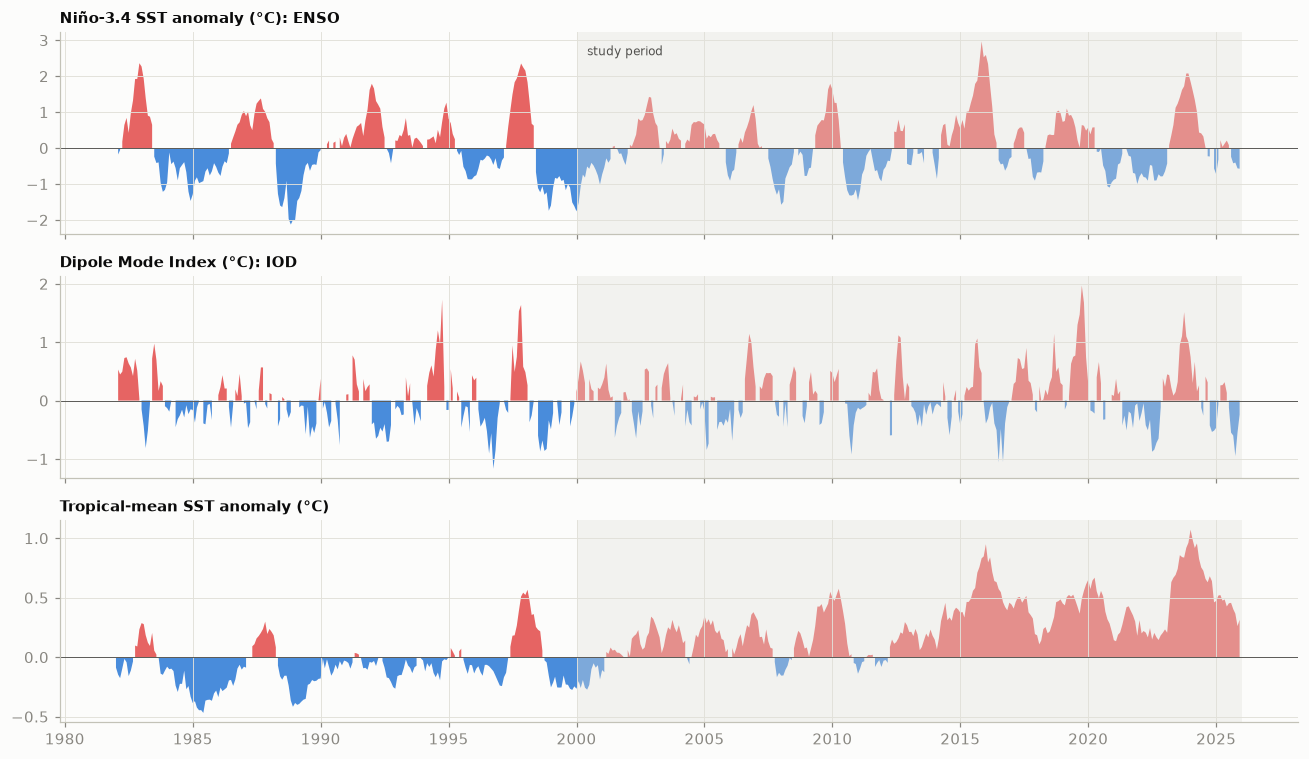

({Timestamp('1997-12-01 00:00:00'): 2.25,
  Timestamp('1998-01-01 00:00:00'): 2.15},
             nino34   dmi
 date                    
 2015-12-01    2.53 -0.03
 2023-12-01    2.08  1.01
 2019-10-01    0.64  1.97)

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, col, title in [(axes[0], "nino34", "Niño-3.4 SST anomaly (°C): ENSO"), (axes[1], "dmi", "Dipole Mode Index (°C): IOD"),
                       (axes[2], "trop_sst", "Tropical-mean SST anomaly (°C)")]:
    s = idx_raw.set_index("date")[col]
    ax.fill_between(s.index, 0, s.where(s > 0), color="#e34948", linewidth=0, alpha=.85)
    ax.fill_between(s.index, 0, s.where(s < 0), color="#2a78d6", linewidth=0, alpha=.85)
    ax.axhline(0, color=V.INK_2, linewidth=.6)
    ax.axvspan(pd.Timestamp("2000-01-01"), pd.Timestamp("2025-12-31"), color=V.GRID, alpha=.35, linewidth=0)
    ax.set_title(title, fontsize=10)
axes[0].annotate("study period", (pd.Timestamp("2000-06-01"), axes[0].get_ylim()[1] * .8), fontsize=8, color=V.INK_2)
fig.tight_layout(); V.save(fig, "oc_01_indices"); plt.show()
idx_raw.set_index("date").loc["1997-12":"1998-01", "nino34"].round(2).to_dict(), idx_raw.set_index("date").loc[["2015-12-01", "2023-12-01", "2019-10-01"], ["nino34", "dmi"]].round(2)

**Validation against known events:** the major El Niños (1997–98, 2015–16, 2023–24), the 2010–11 La Niña and the strong positive IOD of 2019 all appear with the expected sign and size. The tropical-mean SST shows the long-term ocean warming, about +1 °C since the early 1980s relative to the base period.

## 2. Is there a physical link? (training years 2000–2019 only)

For each district we correlate the Tmax anomaly with each index:
* **concurrent:** index and Tmax in the same month, i.e. a physical relationship;
* **lag 1:** index in month t vs Tmax in month t+1, i.e. what a forecast can use.

Spearman correlation per district, by target season. Dots mark districts significant after Benjamini–Hochberg FDR correction (q < 0.05).

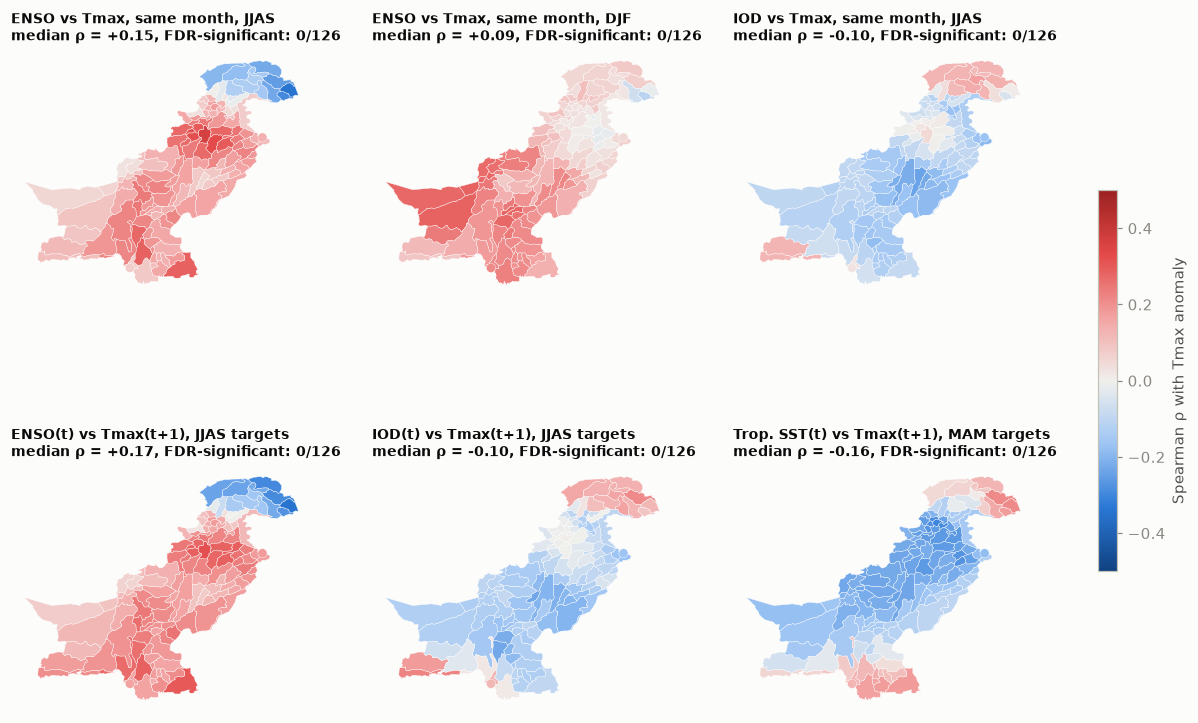

,panel,median rho,significant districts (q<0.05)
0,"ENSO vs Tmax, same month, JJAS",0.145,0
1,"ENSO vs Tmax, same month, DJF",0.094,0
2,"IOD vs Tmax, same month, JJAS",-0.100,0
3,"ENSO(t) vs Tmax(t+1), JJAS targets",0.171,0
4,"IOD(t) vs Tmax(t+1), JJAS targets",-0.104,0
5,"Trop. SST(t) vs Tmax(t+1), MAM targets",-0.165,0


In [3]:
tr = monthly[monthly["year"] <= C.TRAIN_YEARS[1]].sort_values(["district_id", "date"]).copy()
tr["tmax_next"] = tr.groupby("district_id")["tmax_c_anom"].shift(-1)
tr["next_season"] = tr.groupby("district_id")["season"].shift(-1)
ix = idx_raw.set_index("date")
for k in ["nino34", "dmi", "trop_sst"]:
    tr[k] = ix[k].reindex(tr["date"]).to_numpy()

def district_corr(x_col, y_col, season_col, season):
    rows = []
    for did, g in tr[tr[season_col] == season].groupby("district_id"):
        g = g.dropna(subset=[x_col, y_col])
        rho, p = spearmanr(g[x_col], g[y_col])
        rows.append({"district_id": did, "rho": rho, "p": p})
    r = pd.DataFrame(rows)
    r["q"] = false_discovery_control(r["p"], method="bh")
    return r

panels = [("nino34", "tmax_c_anom", "season", "Monsoon (JJAS)", "ENSO vs Tmax, same month, JJAS"),
          ("nino34", "tmax_c_anom", "season", "Winter (DJF)", "ENSO vs Tmax, same month, DJF"),
          ("dmi", "tmax_c_anom", "season", "Monsoon (JJAS)", "IOD vs Tmax, same month, JJAS"),
          ("nino34", "tmax_next", "next_season", "Monsoon (JJAS)", "ENSO(t) vs Tmax(t+1), JJAS targets"),
          ("dmi", "tmax_next", "next_season", "Monsoon (JJAS)", "IOD(t) vs Tmax(t+1), JJAS targets"),
          ("trop_sst", "tmax_next", "next_season", "Pre-monsoon (MAM)", "Trop. SST(t) vs Tmax(t+1), MAM targets")]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
summ = []
for ax, (x, y, sc, s, title) in zip(axes.ravel(), panels):
    r = district_corr(x, y, sc, s)
    g = gdf.merge(r, on="district_id")
    g.plot(column="rho", cmap=V.DIVERGING, norm=V.symmetric_norm(None, .5), ax=ax, edgecolor="white", linewidth=.25)
    sig = g[g["q"] < .05]
    ax.scatter(sig.geometry.representative_point().x, sig.geometry.representative_point().y, s=6, color=V.INK)
    ax.set_title(f"{title}\nmedian ρ = {r['rho'].median():+.2f}, FDR-significant: {len(sig)}/126", fontsize=9); V.map_axes(ax)
    summ.append({"panel": title, "median rho": r["rho"].median(), "significant districts (q<0.05)": len(sig)})
sm = plt.cm.ScalarMappable(cmap=V.DIVERGING, norm=V.symmetric_norm(None, .5))
fig.colorbar(sm, ax=axes, shrink=.5, label="Spearman ρ with Tmax anomaly")
V.save(fig, "oc_02_teleconnection_maps"); plt.show()
pd.DataFrame(summ).round(3)

In [4]:
# National view: index at month t vs national-mean Tmax anomaly at t+1, by target season (training years)
nat = tr.groupby("date").agg(tmax=("tmax_c_anom", "mean"), season=("season", "first")).sort_index()
nat["tmax_next"] = nat["tmax"].shift(-1); nat["next_season"] = nat["season"].shift(-1)
for k in ["nino34", "dmi", "trop_sst"]:
    nat[k] = ix[k].reindex(nat.index)
rows = []
for s in P.SEASON_ORDER:
    g = nat[nat["next_season"] == s].dropna()
    rows.append({"target season": s, **{f"{k}(t) vs national Tmax(t+1)": spearmanr(g[k], g["tmax_next"])[0] for k in ["nino34", "dmi", "trop_sst"]},
                 "national Tmax(t) vs Tmax(t+1)": spearmanr(g["tmax"], g["tmax_next"])[0], "n months": len(g)})
nat_corr = pd.DataFrame(rows).set_index("target season")
nat_corr.round(3)

,nino34(t) vs national Tmax(t+1),dmi(t) vs national Tmax(t+1),trop_sst(t) vs national Tmax(t+1),national Tmax(t) vs Tmax(t+1),n months
target season,,,,,
Winter (DJF),0.091,-0.146,0.128,0.380,59
Pre-monsoon (MAM),-0.120,0.388,-0.179,0.406,60
Monsoon (JJAS),0.207,-0.118,0.111,0.168,80
Post-monsoon (ON),-0.487,-0.380,-0.292,0.173,40


## 3. Which driver helps? Ridge ablation on the leak-free CV folds

Ridge is retuned for each feature set; this takes seconds. Same 4 expanding-window folds as notebook 05, so the numbers are directly comparable with the CV table there.

In [5]:
folds = M.make_cv_folds(monthly)
folds = [dict(f, train=F.add_ocean_features(f["train"], ocean_idx), val=F.add_ocean_features(f["val"], ocean_idx)) for f in folds]
sets = {"Local (notebook 05)": F.FEATURES}
for g, cols in F.OCEAN_GROUPS.items():
    sets[f"Local + {g}"] = F.FEATURES + cols
sets["Local + all ocean drivers"] = F.FEATURES + F.OCEAN_FEATURES
abl = []
for sname, cols in sets.items():
    p, res, _ = M.tune("Ridge", folds, cols)
    abl.append({"feature set": sname, "alpha": p["model__alpha"], **{f"fold {k + 1}": res.loc[0, f"split{k}_val_rmse"] for k in range(4)},
                "mean CV RMSE": res.loc[0, "mean_val_rmse"]})
abl = pd.DataFrame(abl).set_index("feature set")
damp_cv = np.mean([np.sqrt(np.mean((M.fit_damped_phi(f["train"]) * f["val"]["tmax_anom_l0"] - f["val"][F.TARGET]) ** 2)) for f in folds])
abl["Δ vs local"] = abl["mean CV RMSE"] - abl.loc["Local (notebook 05)", "mean CV RMSE"]
abl["Δ vs damped persistence"] = abl["mean CV RMSE"] - damp_cv
abl.to_csv(REP / "ocean_ablation_ridge.csv")
abl.round(4)

,alpha,fold 1,fold 2,fold 3,fold 4,mean CV RMSE,Δ vs local,Δ vs damped persistence
feature set,,,,,,,,
Local (notebook 05),10000.0,1.4803,1.5119,1.3750,1.7575,1.5312,0.0000,0.0111
Local + ENSO (Nino-3.4),10000.0,1.4724,1.5208,1.3789,1.7589,1.5328,0.0016,0.0127
Local + IOD (DMI),10000.0,1.4826,1.5073,1.3691,1.7580,1.5292,-0.0019,0.0092
Local + Tropical SST,10000.0,1.4752,1.5087,1.3799,1.7616,1.5313,0.0002,0.0113
Local + all ocean drivers,10000.0,1.4736,1.5135,1.3698,1.7614,1.5296,-0.0016,0.0095


## 4. All four models, retuned with ocean drivers

For a fair comparison, each model is **re-tuned** with the extended feature set, using the same search spaces and folds as notebook 05. A model that is simply handed extra features with old hyperparameters could be disadvantaged. The local-feature results are taken unchanged from notebooks 05–06.

In [6]:
OCEAN_SET = F.FEATURES + F.OCEAN_FEATURES
best_ocean, cv_ocean = {}, {}
for name in M.MODEL_ORDER:
    params, res, secs = M.tune(name, folds, OCEAN_SET)
    best_ocean[name], cv_ocean[name] = params, res
    print(f"{name:14s} {secs/60:5.1f} min | CV RMSE {res['mean_val_rmse'].iloc[0]:.4f} | {params}")
with open(C.MODELS_DIR / "best_params_ocean.json", "w") as fh:
    json.dump({k: {p: (v.item() if hasattr(v, "item") else v) for p, v in d.items()} for k, d in best_ocean.items()}, fh, indent=2)

Ridge            0.1 min | CV RMSE 1.5296 | {'model__alpha': np.float64(10000.0)}


Random Forest    8.1 min | CV RMSE 1.5480 | {'max_depth': None, 'max_features': 0.4, 'min_samples_leaf': 1000}


XGBoost          3.2 min | CV RMSE 1.5536 | {'colsample_bytree': np.float64(0.31273937997981016), 'learning_rate': np.float64(0.046125236243355884), 'max_depth': 1, 'min_child_weight': 1885, 'reg_lambda': np.float64(886.2326508576241), 'subsample': np.float64(0.8861223846483287)}


SVR              3.9 min | CV RMSE 1.5429 | {'model__C': 0.1, 'model__epsilon': 0.5, 'model__gamma': 0.01}


In [7]:
cv_local = pd.read_csv(REP / "cv_comparison.csv", index_col=0)
cmp_cv = pd.DataFrame({"CV RMSE, local": cv_local.loc[M.MODEL_ORDER, "mean"],
                       "CV RMSE, + ocean": [cv_ocean[n]["mean_val_rmse"].iloc[0] for n in M.MODEL_ORDER]}, index=M.MODEL_ORDER)
cmp_cv["Δ (ocean − local)"] = cmp_cv["CV RMSE, + ocean"] - cmp_cv["CV RMSE, local"]
cmp_cv["folds improved"] = [int(sum(cv_ocean[n].loc[0, f"split{k}_val_rmse"] < cv_local.loc[n, f"fold {k + 1}"] for k in range(4))) for n in M.MODEL_ORDER]
cmp_cv.loc["Damped persistence (reference)"] = [cv_local.loc["Damped persistence", "mean"]] * 2 + [0, np.nan]
cmp_cv.to_csv(REP / "ocean_cv_comparison.csv")
cmp_cv.round(4)

,"CV RMSE, local","CV RMSE, + ocean",Δ (ocean − local),folds improved
Ridge,1.5312,1.5296,-0.0016,2.0
Random Forest,1.5387,1.5480,0.0093,1.0
XGBoost,1.5451,1.5536,0.0085,1.0
SVR,1.5281,1.5429,0.0147,1.0
Damped persistence (reference),1.5201,1.5201,0.0000,NaN


In [8]:
# Final fit on 2000-2022 with ocean drivers, single evaluation on the untouched 2023-2025 test set
feat = F.add_ocean_features(F.load_features(), ocean_idx)
dev = feat[feat["split"] != "test"].reset_index(drop=True)
test = feat[feat["split"] == "test"].reset_index(drop=True)
pred = pd.read_parquet(C.DATA_PROCESSED / "test_predictions.parquet")
assert (pred["district_id"].values == test["district_id"].values).all() and (pred["target_date"].values == test["target_date"].values).all()
for name in M.MODEL_ORDER:
    m = M.fit_model(name, best_ocean[name], dev, OCEAN_SET)
    pred[f"{name} + ocean"] = m.predict(test[OCEAN_SET])
y = pred[F.TARGET]
rows = []
for name in M.MODEL_ORDER:
    loc = M.regression_metrics(y, pred[name], pred["Climatology"], pred["Damped persistence"])
    oc = M.regression_metrics(y, pred[f"{name} + ocean"], pred["Climatology"], pred["Damped persistence"])
    pt, lo, hi = M.bootstrap_skill(pred, f"{name} + ocean", name)
    rows.append({"model": name, "RMSE local": loc["RMSE"], "RMSE + ocean": oc["RMSE"],
                 "skill vs clim, local": loc["Skill vs climatology"], "skill vs clim, + ocean": oc["Skill vs climatology"],
                 "bias local": loc["Bias"], "bias + ocean": oc["Bias"],
                 "skill of ocean vs local": pt, "95% CI low": lo, "95% CI high": hi})
cmp_test = pd.DataFrame(rows).set_index("model")
cmp_test.to_csv(REP / "ocean_test_comparison.csv")
pred.to_parquet(C.DATA_PROCESSED / "test_predictions_ocean.parquet", index=False)
cmp_test.round(4)

,RMSE local,RMSE + ocean,"skill vs clim, local","skill vs clim, + ocean",bias local,bias + ocean,skill of ocean vs local,95% CI low,95% CI high
model,,,,,,,,,
Ridge,1.6733,1.6496,0.0914,0.1170,-0.2875,-0.2272,0.0282,0.0004,0.0576
Random Forest,1.7111,1.6792,0.0500,0.0850,-0.2706,-0.2013,0.0369,-0.0139,0.0942
XGBoost,1.6946,1.6926,0.0682,0.0703,-0.2641,-0.1346,0.0023,-0.0755,0.0705
SVR,1.7059,1.6999,0.0557,0.0624,-0.3285,-0.1627,0.0070,-0.0860,0.0936


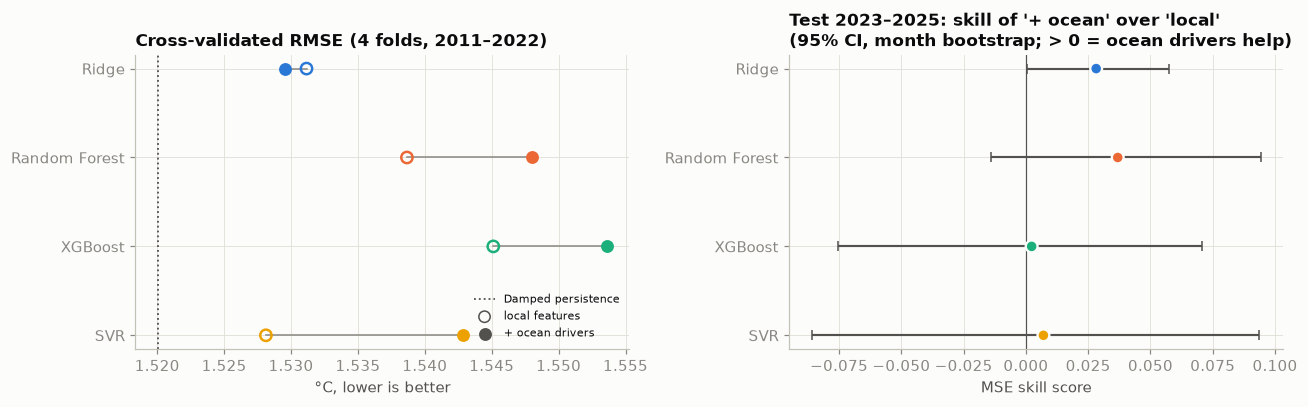

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
yy = np.arange(len(M.MODEL_ORDER))[::-1]
COL = dict(zip(M.MODEL_ORDER, V.CATEGORICAL[:4]))
for k, n in enumerate(M.MODEL_ORDER):
    a, b = cmp_cv.loc[n, "CV RMSE, local"], cmp_cv.loc[n, "CV RMSE, + ocean"]
    ax.plot([a, b], [yy[k]] * 2, color=V.MUTED, linewidth=1)
    ax.scatter(a, yy[k], s=55, facecolor="none", edgecolor=COL[n], linewidth=1.6, zorder=3)
    ax.scatter(b, yy[k], s=55, color=COL[n], zorder=3)
ax.axvline(cmp_cv.loc["Damped persistence (reference)", "CV RMSE, local"], color=V.INK_2, linestyle=":", linewidth=1.2, label="Damped persistence")
ax.scatter([], [], s=55, facecolor="none", edgecolor=V.INK_2, label="local features"); ax.scatter([], [], s=55, color=V.INK_2, label="+ ocean drivers")
ax.set_yticks(yy); ax.set_yticklabels(M.MODEL_ORDER); ax.set(title="Cross-validated RMSE (4 folds, 2011–2022)", xlabel="°C, lower is better")
ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
c = cmp_test
ax.errorbar(c["skill of ocean vs local"], yy, xerr=[c["skill of ocean vs local"] - c["95% CI low"], c["95% CI high"] - c["skill of ocean vs local"]],
            fmt="none", ecolor=V.INK_2, elinewidth=1.4, capsize=3)
ax.scatter(c["skill of ocean vs local"], yy, s=60, color=[COL[n] for n in M.MODEL_ORDER], zorder=3, edgecolor=V.SURFACE, linewidth=1.5)
ax.axvline(0, color=V.INK_2, linewidth=.8)
ax.set_yticks(yy); ax.set_yticklabels(M.MODEL_ORDER)
ax.set(title="Test 2023–2025: skill of '+ ocean' over 'local'\n(95% CI, month bootstrap; > 0 = ocean drivers help)", xlabel="MSE skill score")
fig.tight_layout(); V.save(fig, "oc_03_ocean_vs_local"); plt.show()

## 5. Summary: do ocean drivers help?

All numbers come from the cells above.

**O1. The physical link is weak at district level.** In the training years, no district has an FDR-significant correlation between its Tmax anomaly and ENSO or IOD, either in the same month or one month ahead (median |ρ| ≈ 0.1–0.17). At national level some seasonal links appear (n = 40–80 months, so treat them with caution): ENSO(t) vs Tmax(t+1) for post-monsoon targets ρ = −0.49, and IOD(t) vs Tmax(t+1) for pre-monsoon targets ρ = +0.39. These are as large as the persistence signal itself (ρ ≈ 0.17–0.41), but they only hold in some seasons.

**O2. Cross-validation (2011–2022): no robust gain.** For Ridge, adding all ocean drivers changes CV RMSE by −0.002 °C (IOD alone: −0.002; ENSO alone: +0.002). For Random Forest, XGBoost and SVR, the ocean features make CV RMSE *worse* (+0.009 to +0.015 °C), with only 1 of 4 folds improved. No model with ocean drivers beats damped persistence on CV.

**O3. Test set (2023–2025): every model improves, and the gain is significant for Ridge.** RMSE decreases for all four models. Ridge + ocean reaches RMSE 1.650 °C and skill +11.7% vs climatology, up from +9.1% with local features. The improvement over local Ridge is +2.8% MSE skill with a 95% CI of [+0.04%, +5.8%], just above zero. Against damped persistence, Ridge + ocean scores +4.6% (CI −1.7% to +10.5%, not significant). The gain is not driven only by the 2023–24 El Niño: per-year RMSE improves most in 2025 (1.404 → 1.347 °C).

**O4. Ocean drivers reduce the warming bias.** The mean under-prediction (finding M5) shrinks for every model: Ridge −0.29 → −0.23 °C, XGBoost −0.26 → −0.13 °C, SVR −0.33 → −0.16 °C. The tropical-SST index carries the background warming that the anomaly-based local features cannot.

**O5. Interpretation (reasoning, not just scores).** CV and test disagree. The likely reason is the warming trend: CV folds 1–3 fall in years with little ocean-warming contrast relative to their training data, while 2023–2025 is clearly warmer than 2000–2022 (tropical SST +0.4 to +0.8 °C). In that setting an index that tracks warming becomes useful. Tree models gain least on CV because they cannot extrapolate a trending predictor beyond its training range.
**Conclusion for H1:** ocean drivers give a small, significant improvement for the best model (Ridge) on the most recent, warmest years, mainly by reducing the warming bias. The gain is not robust across earlier periods. We therefore report Ridge + ocean drivers as the **best-performing configuration**, while stating clearly that its advantage over damped persistence is not statistically established.